<a href="https://colab.research.google.com/github/Jhonatasm1/analise_naca4412/blob/main/projetos1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np


def converter_bsfc_para_si(valor, unidade_origem, g=9.80665):
    """
    Converte o consumo específico de potência (BSFC) para N/(W*s) [1/m].
    """
    if unidade_origem == "SI":  # já em N/(W*s) ou 1/m
        return valor
    elif unidade_origem == "kg/(W*s)":
        return valor * g
    elif unidade_origem == "g/(kW*h)":
        # 1 g = 1e-3 kg | 1 kW = 1000 W | 1 h = 3600 s
        c_massa = (valor * 1e-3) / (1000 * 3600)
        return c_massa * g
    elif unidade_origem == "lb/(hp*h)":
        # 1 lb = 0.45359237 kg | 1 hp = 745.7 W | 1 h = 3600 s
        c_massa = (valor * 0.45359237) / (745.7 * 3600)
        return c_massa * g
    else:
        raise ValueError(
            "Unidade não reconhecida. Use 'SI', 'kg/(W*s)', 'g/(kW*h)' ou 'lb/(hp*h)'."
        )


def calcular_autonomia_helice(eta, c_si, cl, cd, rho, S, W1, W2):
    """
    Calcula a autonomia (Endurance) para aeronaves a hélice (Equação de Breguet).
    Todas as entradas devem estar no Sistema Internacional (SI).
    Retorna a autonomia em segundos e em horas.
    """
    if W2 >= W1:
        raise ValueError(
            "O peso final (W2) deve ser menor que o peso inicial (W1)."
        )

    termo_propulsivo = eta / c_si
    termo_aerodinamico = (cl**1.5) / cd
    termo_atmosferico_geo = np.sqrt(2 * rho * S)
    termo_peso = (1 / np.sqrt(W2)) - (1 / np.sqrt(W1))

    E_segundos = (
        termo_propulsivo
        * termo_aerodinamico
        * termo_atmosferico_geo
        * termo_peso
    )
    E_horas = E_segundos / 3600.0

    return E_segundos, E_horas


# ==========================================
# EXEMPLO DE USO
# ==========================================
if __name__ == "__main__":
    g = 9.80665  # m/s^2

    # Dados de entrada
    eta = 0.80  # Eficiência da hélice [-]
    c_raw = 0.45  # BSFC típico de motor a pistão [lb/(hp*h)]
    cl = 0.3417  # Coeficiente de sustentação [-]
    cd = 0.02876  # Coeficiente de arrasto [-]
    rho = 1.225  # Densidade do ar [kg/m^3]
    S = 14.8  # Área alar [m^2]

    massa_inicial = 1394.96  # [kg]
    massa_final = 1335.46

    # Conversões para o SI
    c_si = converter_bsfc_para_si(c_raw, unidade_origem="lb/(hp*h)", g=g)
    W1 = massa_inicial * g  # Peso inicial [N]
    W2 = massa_final * g  # Peso final [N]

    # Cálculo
    autonomia_s, autonomia_h = calcular_autonomia_helice(
        eta, c_si, cl, cd, rho, S, W1, W2
    )

    print(f"BSFC convertido: {c_si:.4e} N/(W*s)")
    print(f"Autonomia: {autonomia_s:.1f} segundos ({autonomia_h:.2f} horas)")

BSFC convertido: 7.4565e-07 N/(W*s)
Autonomia: 8452.9 segundos (2.35 horas)


In [ ]:

import math
import pandas as pd

# ============================================================
# 1. DADOS GEOMETRICOS DA AERONAVE
# ============================================================

S_ref = 14.48  # Área de referência da asa (m²)

# ---------------- FUSELAGEM ----------------

L_fus = 7.867
W_fus = 1.40
H_fus = 1.45
K_fus = 3.4

# ---------------- ASA ----------------

S_asa = 14.48
tc_asa = 0.18
c_media_asa = 1.44

# Área exposta da asa (m²)
# PREENCHER com a área da asa que não fica coberta pela fuselagem.
# Se não souber, deixe None para não calcular essa contribuição.
S_asa_exposta = 11.89

# Dados necessários para o fator de forma da asa
xc_asa = 0.30
enflechamento_asa = 0  # Enflechamento da linha de espessura máxima (graus)

# ---------------- EMPENAGEM HORIZONTAL ----------------

S_H = 2.408
tc_H = 0.12  # SUBSTITUIR pela espessura relativa real
c_H = 0.813

xc_H = 0.3
enflechamento_H = 0  # Enflechamento da linha de espessura máxima (graus)

# ---------------- EMPENAGEM VERTICAL ----------------

S_V = 1.386
tc_V = 0.15  # SUBSTITUIR pela espessura relativa real
c_V = 1.213

xc_V = 0.3
enflechamento_V = 30  # Enflechamento da linha de espessura máxima (graus)


# ============================================================
# 2. CONDICOES DE VOO
# ============================================================

condicoes = {

    "Cruzeiro": {
        "V": 85.0,
        "rho": 0.9093,
        "mu": 1.70e-5,
        "M": 0.2497
    },

    "Decolagem": {
        "V": 37.35,
        "rho": 1.225,
        "mu": 1.789e-5,
        "M": 0.109
    },

    "Pouso": {
        "V": 38.91,
        "rho": 1.225,
        "mu": 1.789e-5,
        "M": 0.113
    }
}


# ============================================================
# 3. FATORES DE CORRECAO
# ============================================================

Q_fus = 1.0
Q_asa = 1.0
Q_H = 1.0
Q_V = 1.0


# ============================================================
# 4. FUNCAO PARA CALCULAR O FATOR DE FORMA
# ============================================================

def calcular_FF(tc, xc, enflechamento, M):

    # Verifica se todos os dados foram preenchidos
    if any(valor is None for valor in [tc, xc, enflechamento, M]):
        return None

    Lambda = math.radians(enflechamento)

    FF = (
        1 + (0.6 / xc) * tc + 100 * tc**4
    ) * (
        1.34 * M**0.18 * math.cos(Lambda)**0.28
    )

    return FF


# ============================================================
# 5. FUNCAO PARA CALCULAR O FATOR DE ATRITO
# ============================================================

def calcular_Cf(Re, M):

    if Re <= 0:
        raise ValueError("O número de Reynolds deve ser positivo.")

    Cf = 0.455 / (
        (math.log10(Re)**2.58) *
        (1 + 0.144 * M**2)**0.65
    )

    return Cf


# ============================================================
# 6. CALCULO DO ARRASTO DA FUSELAGEM
# ============================================================

def arrasto_fuselagem(V, rho, mu, M):

    A_max = math.pi * W_fus * H_fus / 4

    d_eq = math.sqrt(4 * A_max / math.pi)

    f = L_fus / d_eq

    FF = 1 + 60 / (f**3) + f / 400

    Re = rho * V * L_fus / mu

    Cf = calcular_Cf(Re, M)

    A_top = math.pi * L_fus * W_fus / 4
    A_side = math.pi * L_fus * H_fus / 4

    S_wet = K_fus * (A_top + A_side) / 2

    CD0 = Cf * FF * Q_fus * S_wet / S_ref

    return CD0


# ============================================================
# 7. CALCULO DO ARRASTO DA ASA
# ============================================================

def arrasto_asa(V, rho, mu, M):

    if S_asa_exposta is None:
        return None

    FF = calcular_FF(
        tc_asa, xc_asa, enflechamento_asa, M
    )

    if FF is None:
        return None

    Re = rho * V * c_media_asa / mu

    Cf = calcular_Cf(Re, M)

    S_wet = S_asa_exposta * (1.977 + 0.52 * tc_asa)

    CD0 = Cf * FF * Q_asa * S_wet / S_ref

    return CD0


# ============================================================
# 8. CALCULO DO ARRASTO DAS EMPENAGENS
# ============================================================

def arrasto_empennagem(V, rho, mu, M):

    # Fatores de forma calculados para o Mach da condição
    FF_H = calcular_FF(tc_H, xc_H, enflechamento_H, M)

    FF_V = calcular_FF(tc_V, xc_V, enflechamento_V, M)

    # Empenagem horizontal
    CD0_H = None

    if FF_H is not None:

        Re_H = rho * V * c_H / mu

        Cf_H = calcular_Cf(Re_H, M)

        S_wet_H = 2 * S_H * (1 + 0.25 * tc_H)

        CD0_H = Cf_H * FF_H * Q_H * S_wet_H / S_ref

    # Empenagem vertical
    CD0_V = None

    if FF_V is not None:

        Re_V = rho * V * c_V / mu

        Cf_V = calcular_Cf(Re_V, M)

        S_wet_V = 2 * S_V * (1 + 0.25 * tc_V)

        CD0_V = Cf_V * FF_V * Q_V * S_wet_V / S_ref

    return CD0_H, CD0_V


# ============================================================
# 9. INTERFERENCIA ASA-FUSELAGEM
# ============================================================

def interferencia_asa_fuselagem(CD0_fus):

    # Aproximação de 5% adotada no relatório de referência
    return 0.05 * CD0_fus


# ============================================================
# 10. CALCULO DO ARRASTO DO TREM DE POUSO (RAYMER)
# ============================================================

# ---------------- RODAS PRINCIPAIS ----------------

d_main_tire = 0.464        # Diâmetro das rodas principais (m)
w_main_tire = 0.119       # Largura das rodas principais (m)

# ---------------- RODA DO NARIZ ----------------

d_nose_tire = 0.337       # Diâmetro da roda do nariz (m)
w_nose_tire = 0.128       # Largura da roda do nariz (m)

# ---------------- PERNAS DO TREM PRINCIPAL ----------------

d_strut_main = 0.0319      # Diâmetro externo das pernas principais (m)
L_strut_main = 1.05      # Comprimento exposto das pernas principais (m)

# ---------------- PERNA DO TREM DO NARIZ ----------------

d_strut_nose = 0.0312      # Diâmetro externo da perna do nariz (m)
L_strut_nose = 1.17      # Comprimento exposto da perna do nariz (m)

# ---------------- COEFICIENTES DE ARRASTO ----------------

Cd_pi_main_tire = 0.25   # Coeficiente das rodas principais
Cd_pi_nose_tire = 0.25   # Coeficiente da roda do nariz
Cd_pi_strut = 0.3       # Coeficiente das pernas do trem

# Fator de interferência do trem de pouso
K_gear_interf = 1.2


def arrasto_trem_pouso():

    # Verifica se todos os dados foram preenchidos
    dados = [
        d_main_tire,
        w_main_tire,
        d_nose_tire,
        w_nose_tire,
        d_strut_main,
        L_strut_main,
        d_strut_nose,
        L_strut_nose,
        Cd_pi_main_tire,
        Cd_pi_nose_tire,
        Cd_pi_strut,
        K_gear_interf
    ]

    if any(valor is None for valor in dados):
        return None

    # --------------------------------------------------------
    # 1. AREAS FRONTAIS DOS PNEUS
    # --------------------------------------------------------

    A_main_tires = 2 * (d_main_tire * w_main_tire)

    A_nose_tire = 1 * (d_nose_tire * w_nose_tire)

    # --------------------------------------------------------
    # 2. AREAS FRONTAIS DAS PERNAS
    # --------------------------------------------------------

    A_main_struts = 2 * (d_strut_main * L_strut_main)

    A_nose_struts = 1 * (d_strut_nose * L_strut_nose)

    # --------------------------------------------------------
    # 3. ARRASTO BASE DO TREM DE POUSO
    # --------------------------------------------------------

    D_q_gear_base = (
        Cd_pi_main_tire * A_main_tires
        + Cd_pi_nose_tire * A_nose_tire
        + Cd_pi_strut * A_main_struts
        + Cd_pi_strut * A_nose_struts
    )

    # --------------------------------------------------------
    # 4. CORRECAO DE INTERFERENCIA
    # --------------------------------------------------------

    D_q_gear_total = K_gear_interf * D_q_gear_base

    # --------------------------------------------------------
    # 5. COEFICIENTE DE ARRASTO DO TREM
    # --------------------------------------------------------

    delta_CD0_gear = D_q_gear_total / S_ref

    return delta_CD0_gear

# ============================================================
# 10.1 MARGEM PARA PROTUBERANCIAS E ARRASTO DOS FLAPS
# ============================================================

# Margem adicional para protuberâncias
margem_protuberancias = 0.08  # 8%

# Incrementos de arrasto dos flaps
delta_CD0_flaps_decolagem = 0.010
delta_CD0_flaps_pouso = 0.025

# ============================================================
# 11. CALCULO PARA CADA CONDICAO DE VOO
# ============================================================

resultados = []

for nome, dados in condicoes.items():

    V = dados["V"]
    rho = dados["rho"]
    mu = dados["mu"]
    M = dados["M"]

    # --------------------------------------------------------
    # 1. ARRASTO DE CADA COMPONENTE
    # --------------------------------------------------------

    fus = arrasto_fuselagem(V, rho, mu, M)

    asa = arrasto_asa(V, rho, mu, M)

    emp_H, emp_V = arrasto_empennagem(V, rho, mu, M)

    # Interferência asa-fuselagem
    int_asa_fus = interferencia_asa_fuselagem(fus)

    # --------------------------------------------------------
    # 2. ARRASTO BASE
    # --------------------------------------------------------

    componentes = [
        fus,
        asa,
        emp_H,
        emp_V,
        int_asa_fus
    ]

    CD0_base = sum(
        valor for valor in componentes
        if valor is not None
    )

    # --------------------------------------------------------
    # 3. MARGEM PARA PROTUBERANCIAS
    # --------------------------------------------------------

    margem = CD0_base * margem_protuberancias

    CD0_com_margem = CD0_base + margem

    # --------------------------------------------------------
    # 4. ARRASTO DO TREM DE POUSO
    # --------------------------------------------------------

    if nome in ["Decolagem", "Pouso"]:

        trem = arrasto_trem_pouso()

    else:

        # Trem recolhido durante o cruzeiro
        trem = 0.0

    # --------------------------------------------------------
    # 5. ARRASTO DOS FLAPS
    # --------------------------------------------------------

    if nome == "Decolagem":

        flaps = delta_CD0_flaps_decolagem

    elif nome == "Pouso":

        flaps = delta_CD0_flaps_pouso

    else:

        # Flaps recolhidos durante o cruzeiro
        flaps = 0.0

    # --------------------------------------------------------
    # 6. CD0 TOTAL
    # --------------------------------------------------------

    contribuicoes = [
        CD0_com_margem,
        trem,
        flaps
    ]

    CD0_total = sum(
        valor for valor in contribuicoes
        if valor is not None
    )

    # --------------------------------------------------------
    # 7. ORGANIZACAO DOS RESULTADOS
    # --------------------------------------------------------

    resultados.append({

        "Condição": nome,

        "Fuselagem": fus,
        "Asa": asa,
        "Empenagem horizontal": emp_H,
        "Empenagem vertical": emp_V,

        "Interferência asa-fuselagem": int_asa_fus,

        "CD0 base": CD0_base,

        "Margem protuberâncias": margem,

        "Trem de pouso": trem,

        "Flaps": flaps,

        "CD0 total": CD0_total

    })


# ============================================================
# 12. EXIBICAO DOS RESULTADOS
# ============================================================

tabela = pd.DataFrame(resultados)

print("\nCONTRIBUIÇÕES INDIVIDUAIS DE ARRASTO")
print("(Valores em coeficientes de arrasto)")

print(tabela.to_string(index=False))

# ============================================================
# 12. EXIBICAO DOS RESULTADOS
# ============================================================

tabela = pd.DataFrame(resultados)

print("\nCONTRIBUIÇÕES INDIVIDUAIS DE ARRASTO")
print("(Valores em coeficientes de arrasto)")

print(tabela.to_string(index=False))


# ============================================================
# 13. EXIBICAO DOS FATORES DE FORMA
# ============================================================

print("\nFATORES DE FORMA POR CONDIÇÃO DE VOO")

for nome, dados in condicoes.items():

    M = dados["M"]

    FF_asa = calcular_FF(
        tc_asa, xc_asa, enflechamento_asa, M
    )

    FF_H = calcular_FF(
        tc_H, xc_H, enflechamento_H, M
    )

    FF_V = calcular_FF(
        tc_V, xc_V, enflechamento_V, M
    )

    print(f"\n{nome}:")
    print(f"FF da asa: {FF_asa}")
    print(f"FF da empenagem horizontal: {FF_H}")
    print(f"FF da empenagem vertical: {FF_V}")



CONTRIBUIÇÕES INDIVIDUAIS DE ARRASTO
(Valores em coeficientes de arrasto)
 Condição  Fuselagem      Asa  Empenagem horizontal  Empenagem vertical  Interferência asa-fuselagem  CD0 base  Margem protuberâncias  Trem de pouso  Flaps  CD0 total
 Cruzeiro   0.006952 0.008317              0.001587            0.000885                     0.000348  0.018088               0.001447       0.000000  0.000   0.019535
Decolagem   0.007618 0.007926              0.001518            0.000844                     0.000381  0.018287               0.001463       0.005755  0.010   0.035504
    Pouso   0.007569 0.007921              0.001517            0.000844                     0.000378  0.018230               0.001458       0.005755  0.025   0.050443

CONTRIBUIÇÕES INDIVIDUAIS DE ARRASTO
(Valores em coeficientes de arrasto)
 Condição  Fuselagem      Asa  Empenagem horizontal  Empenagem vertical  Interferência asa-fuselagem  CD0 base  Margem protuberâncias  Trem de pouso  Flaps  CD0 total
 Cruzeiro   0.0

In [ ]:

import math
import pandas as pd

# =====================================================
# 1. DADOS DA AERONAVE
# =====================================================

g = 9.80665
massa = 1460       # kg
W = massa * g      # N

S = 14.48          # Área da asa (m²)

# Comprimentos característicos (m)
L_fus = 7.867
MAC_asa = 1.44
MAC_H = 0.813
MAC_V = 1.213

# Coeficientes máximos de sustentação
CLmax_limpo = 1.35
CLmax_TO = 1.666
CLmax_pouso = 1.802

# =====================================================
# 2. ATMOSFERA
# =====================================================

# Decolagem e pouso: nível do mar, atmosfera ISA
rho_TO = 1.225
mu_TO = 1.789e-5

rho_pouso = 1.225
mu_pouso = 1.789e-5

# Cruzeiro: valores já utilizados no relatório
rho_cr = 0.9093
mu_cr = 1.70e-5

# =====================================================
# 3. VELOCIDADES
# =====================================================

# Velocidade de cruzeiro
V_cr = 85.0

# Velocidades de estol
def velocidade_estol(rho, CLmax):
    return math.sqrt(2 * W / (rho * S * CLmax))

Vs_TO = velocidade_estol(rho_TO, CLmax_TO)
Vs_pouso = velocidade_estol(rho_pouso, CLmax_pouso)

# Fatores operacionais preliminares
FATOR_TO = 1.20
FATOR_POUSO = 1.30

# Velocidades representativas adotadas
V_TO = FATOR_TO * Vs_TO
V_pouso = FATOR_POUSO * Vs_pouso

# =====================================================
# 4. ORGANIZAÇÃO DAS CONDIÇÕES
# =====================================================

condicoes = {
    "Cruzeiro": {
        "V": V_cr,
        "rho": rho_cr,
        "mu": mu_cr
    },

    "Decolagem": {
        "V": V_TO,
        "rho": rho_TO,
        "mu": mu_TO
    },

    "Pouso": {
        "V": V_pouso,
        "rho": rho_pouso,
        "mu": mu_pouso
    }
}

# =====================================================
# 5. COMPRIMENTOS DE REFERÊNCIA
# =====================================================

componentes = {
    "Fuselagem": L_fus,
    "Asa": MAC_asa,
    "Empenagem horizontal": MAC_H,
    "Empenagem vertical": MAC_V
}

# =====================================================
# 6. CÁLCULO DOS NÚMEROS DE REYNOLDS
# =====================================================

resultados = []

for condicao, dados in condicoes.items():

    V = dados["V"]
    rho = dados["rho"]
    mu = dados["mu"]

    for componente, comprimento in componentes.items():

        Re = (rho * V * comprimento) / mu

        resultados.append({
            "Condição": condicao,
            "Componente": componente,
            "Velocidade (m/s)": V,
            "Reynolds": Re
        })

# =====================================================
# 7. RESULTADOS
# =====================================================

print("VELOCIDADES CALCULADAS")
print(f"Velocidade de estol na decolagem: {Vs_TO:.2f} m/s")
print(f"Velocidade adotada na decolagem: {V_TO:.2f} m/s")
print(f"Velocidade de estol no pouso: {Vs_pouso:.2f} m/s")
print(f"Velocidade adotada no pouso: {V_pouso:.2f} m/s")

tabela = pd.DataFrame(resultados)

print("\nNÚMEROS DE REYNOLDS")
print(tabela.to_string(index=False))


VELOCIDADES CALCULADAS
Velocidade de estol na decolagem: 31.13 m/s
Velocidade adotada na decolagem: 37.35 m/s
Velocidade de estol no pouso: 29.93 m/s
Velocidade adotada no pouso: 38.91 m/s

NÚMEROS DE REYNOLDS
 Condição           Componente  Velocidade (m/s)     Reynolds
 Cruzeiro            Fuselagem         85.000000 3.576732e+07
 Cruzeiro                  Asa         85.000000 6.546960e+06
 Cruzeiro Empenagem horizontal         85.000000 3.696304e+06
 Cruzeiro   Empenagem vertical         85.000000 5.514904e+06
Decolagem            Fuselagem         37.354522 2.012232e+07
Decolagem                  Asa         37.354522 3.683252e+06
Decolagem Empenagem horizontal         37.354522 2.079503e+06
Decolagem   Empenagem vertical         37.354522 3.102628e+06
    Pouso            Fuselagem         38.910373 2.096044e+07
    Pouso                  Asa         38.910373 3.836663e+06
    Pouso Empenagem horizontal         38.910373 2.166116e+06
    Pouso   Empenagem vertical         38.9103

In [ ]:
"""
Arrasto parasita (CD0) pelo metodo de component buildup do Raymer
Condicoes: cruzeiro, decolagem e pouso

CD0 = [ sum(Cf * FF * Q * S_wet) / S_ref ] * (1 + protuberancias)
      + trem de pouso + flaps + arrasto extra (refrigeracao etc.)

Itens marcados com  >>> PREENCHER <<<  dependem de dados da sua aeronave.
Se um dado ficar como None, o codigo avisa e ignora aquela contribuicao
(ou usa uma estimativa, quando indicado).
"""

import math
import pandas as pd

avisos = []  # lista de avisos mostrados no final


# ============================================================
# 1. DADOS GEOMETRICOS DA AERONAVE
# ============================================================

S_ref = 14.48  # Area de referencia da asa (m2)

# ---------------- FUSELAGEM ----------------
L_fus = 7.867      # comprimento (m)
W_fus = 1.40       # largura maxima (m)
H_fus = 1.45       # altura maxima (m)
K_fus = 3.4        # Raymer: S_wet = K * (A_top + A_side) / 2

# >>> PREENCHER <<<  Areas projetadas reais da fuselagem (m2), medidas no
# desenho/CAD (vista superior e vista lateral). Se None, usa estimativa
# elíptica (pi/4 * L * dimensao), que tende a subestimar a area real.
A_top_fus = None
A_side_fus = None

# ---------------- ASA ----------------
tc_asa = 0.18
c_media_asa = 1.44         # corda media aerodinamica (m)
S_asa_exposta = 11.89      # area exposta (m2)
xc_asa = 0.30              # posicao da espessura maxima (x/c)
enflechamento_asa = 0      # enflechamento da linha de espessura maxima (graus)

# ---------------- EMPENAGEM HORIZONTAL ----------------
tc_H = 0.12                # >>> CONFIRMAR <<< espessura relativa real
c_H = 0.813                # corda media (m)
xc_H = 0.30
enflechamento_H = 0
S_H = 2.408                # area total (m2)
# >>> PREENCHER <<<  area exposta (fora da fuselagem). Se None, usa S_H.
S_H_exposta = None

# ---------------- EMPENAGEM VERTICAL ----------------
tc_V = 0.15                # >>> CONFIRMAR <<< espessura relativa real
c_V = 1.213                # corda media (m)
xc_V = 0.30
enflechamento_V = 30
S_V = 1.386                # area total (m2)
# >>> PREENCHER <<<  area exposta. Se None, usa S_V.
S_V_exposta = None


# ============================================================
# 2. CONDICOES DE VOO (atmosfera ISA calculada pela altitude)
# ============================================================
# Velocidade e altitude de cada condicao.
# Cruzeiro: rho = 0.9093 kg/m3 corresponde a ~3000 m ISA.
# >>> PREENCHER <<<  altitudes (m) e dT_ISA (K) se nao for atmosfera padrao.

condicoes_entrada = {
    "Cruzeiro":  {"V": 85.0,  "h": 3000.0, "dT_ISA": 0.0},
    "Decolagem": {"V": 37.35, "h": 0.0,    "dT_ISA": 0.0},
    "Pouso":     {"V": 38.91, "h": 0.0,    "dT_ISA": 0.0},
}


def atmosfera_isa(h, dT=0.0):
    """ISA na troposfera (h <= 11000 m). Retorna rho, mu, a."""
    T0, p0, L, R, g, gamma = 288.15, 101325.0, 0.0065, 287.053, 9.80665, 1.4
    T_std = T0 - L * h
    p = p0 * (T_std / T0) ** (g / (R * L))
    T = T_std + dT
    rho = p / (R * T)
    a = math.sqrt(gamma * R * T)
    mu = 1.458e-6 * T ** 1.5 / (T + 110.4)  # Sutherland
    return rho, mu, a


condicoes = {}
for nome, d in condicoes_entrada.items():
    rho, mu, a = atmosfera_isa(d["h"], d["dT_ISA"])
    condicoes[nome] = {"V": d["V"], "rho": rho, "mu": mu, "a": a,
                       "M": d["V"] / a}


# ============================================================
# 3. FATORES DE INTERFERENCIA (Q) E ACABAMENTO
# ============================================================

Q_fus = 1.0
Q_asa = 1.4    # >>> CONFIRMAR <<< 1.0 para asa alta/media bem carenada;
               # valores maiores (ate ~1.4) para asa baixa sem carenagem
Q_H = 1.04     # Raymer: empenagem convencional ~1.03 a 1.08
Q_V = 1.04

# Rugosidade equivalente da superficie k (m)  >>> PREENCHER <<<
# Raymer (convertido de ft): tinta lisa 6.3e-6 | chapa de producao 4.1e-6
# tinta camuflagem em aluminio 1.0e-5 | polida 1.5e-6 | composito liso 5.2e-7
k_rugosidade = 6.34e-6

# Fracao de escoamento laminar por componente (0 = 100% turbulento, conservador)
pct_lam = {"fus": 0.0, "asa": 0.0, "H": 0.0, "V": 0.0}


# ============================================================
# 4. FUNCOES BASICAS
# ============================================================

def Re_corte(comprimento):
    """Reynolds de corte por rugosidade (Raymer, subsonico)."""
    return 38.21 * (comprimento / k_rugosidade) ** 1.053


def reynolds_efetivo(rho, V, comprimento, mu):
    """Menor entre o Re real e o Re de corte por rugosidade."""
    return min(rho * V * comprimento / mu, Re_corte(comprimento))


def calcular_Cf(Re, M, lam=0.0):
    """Cf medio: mistura laminar/turbulento (lam = fracao laminar)."""
    if Re <= 0:
        raise ValueError("O numero de Reynolds deve ser positivo.")
    Cf_turb = 0.455 / ((math.log10(Re) ** 2.58) * (1 + 0.144 * M ** 2) ** 0.65)
    Cf_lam = 1.328 / math.sqrt(Re)
    return lam * Cf_lam + (1 - lam) * Cf_turb


def calcular_FF_superficie(tc, xc, enflechamento, M):
    """Fator de forma de asa/empenagem (Raymer)."""
    Lam = math.radians(enflechamento)
    return (1 + (0.6 / xc) * tc + 100 * tc ** 4) * \
           (1.34 * M ** 0.18 * math.cos(Lam) ** 0.28)


def calcular_FF_fuselagem(f):
    """Fator de forma da fuselagem (Raymer, edicoes recentes)."""
    return 0.9 + 5 / f ** 1.5 + f / 400


# ============================================================
# 5. COMPONENTES
# ============================================================

def arrasto_fuselagem(V, rho, mu, M):
    A_max = math.pi * W_fus * H_fus / 4          # secao elíptica
    d_eq = math.sqrt(4 * A_max / math.pi)
    f = L_fus / d_eq
    FF = calcular_FF_fuselagem(f)

    A_top = A_top_fus if A_top_fus is not None else math.pi * L_fus * W_fus / 4
    A_side = A_side_fus if A_side_fus is not None else math.pi * L_fus * H_fus / 4
    S_wet = K_fus * (A_top + A_side) / 2

    Re = reynolds_efetivo(rho, V, L_fus, mu)
    Cf = calcular_Cf(Re, M, pct_lam["fus"])
    return Cf * FF * Q_fus * S_wet / S_ref


def arrasto_superficie(V, rho, mu, M, corda, tc, xc, enfl, S_exp, Q, lam):
    """Asa ou empenagem, com a mesma formulacao de S_wet."""
    FF = calcular_FF_superficie(tc, xc, enfl, M)
    Re = reynolds_efetivo(rho, V, corda, mu)
    Cf = calcular_Cf(Re, M, lam)
    S_wet = S_exp * (1.977 + 0.52 * tc)
    return Cf * FF * Q * S_wet / S_ref


def arrasto_asa(V, rho, mu, M):
    return arrasto_superficie(V, rho, mu, M, c_media_asa, tc_asa, xc_asa,
                              enflechamento_asa, S_asa_exposta, Q_asa,
                              pct_lam["asa"])


def arrasto_empenagens(V, rho, mu, M):
    S_H_e = S_H_exposta if S_H_exposta is not None else S_H
    S_V_e = S_V_exposta if S_V_exposta is not None else S_V
    cd_H = arrasto_superficie(V, rho, mu, M, c_H, tc_H, xc_H,
                              enflechamento_H, S_H_e, Q_H, pct_lam["H"])
    cd_V = arrasto_superficie(V, rho, mu, M, c_V, tc_V, xc_V,
                              enflechamento_V, S_V_e, Q_V, pct_lam["V"])
    return cd_H, cd_V


if A_top_fus is None or A_side_fus is None:
    avisos.append("Areas projetadas da fuselagem nao informadas: usada "
                  "estimativa elíptica (pi/4*L*dimensao).")
if S_H_exposta is None or S_V_exposta is None:
    avisos.append("Area exposta das empenagens nao informada: usada a area "
                  "total (S_H / S_V), o que superestima o arrasto.")


# ============================================================
# 6. TREM DE POUSO (Raymer, D/q por area frontal x Cd)
# ============================================================

d_main_tire = 0.464        # diametro das rodas principais (m)
w_main_tire = 0.119        # largura das rodas principais (m)
d_nose_tire = 0.337        # diametro da roda do nariz (m)
w_nose_tire = 0.128        # largura da roda do nariz (m)
d_strut_main = 0.0319      # diametro das pernas principais (m)
L_strut_main = 1.05        # comprimento exposto das pernas principais (m)
d_strut_nose = 0.0312      # diametro da perna do nariz (m)
L_strut_nose = 1.17        # comprimento exposto da perna do nariz (m)

Cd_pi_main_tire = 0.25
Cd_pi_nose_tire = 0.25
Cd_pi_strut = 0.30
K_gear_interf = 1.2        # >>> CONFIRMAR <<< na edicao do Raymer que voce usa


def arrasto_trem_pouso():
    A_main_tires = 2 * d_main_tire * w_main_tire
    A_nose_tire = d_nose_tire * w_nose_tire
    A_main_struts = 2 * d_strut_main * L_strut_main
    A_nose_strut = d_strut_nose * L_strut_nose

    D_q = (Cd_pi_main_tire * A_main_tires
           + Cd_pi_nose_tire * A_nose_tire
           + Cd_pi_strut * (A_main_struts + A_nose_strut))
    return K_gear_interf * D_q / S_ref


# ============================================================
# 7. FLAPS (Raymer): dCD0 = F * (cf/c) * (S_flapped/S_ref) * (delta - 10)
# ============================================================

# >>> PREENCHER <<<
tipo_flap = "simples"        # "simples" (F=0.0144) ou "ranhurado" (F=0.0074)
cf_c = 0.3                  # razao corda do flap / corda da asa
S_flapped = 8.08             # area da asa afetada pelos flaps (m2)
delta_flap_decolagem = 10  # deflexao na decolagem (graus)
delta_flap_pouso = 30      # deflexao no pouso (graus)

F_FLAP = {"simples": 0.0144, "ranhurado": 0.0074}


def delta_CD0_flaps(delta_deg):
    if None in (cf_c, S_flapped, delta_deg):
        return None
    if delta_deg <= 10:
        return 0.0
    return F_FLAP[tipo_flap] * cf_c * (S_flapped / S_ref) * (delta_deg - 10)


# ============================================================
# 8. MARGENS E ARRASTO EXTRA
# ============================================================

margem_protuberancias = 0.08   # protuberancias e vazamentos (Raymer: ~2 a 10%)

# >>> PREENCHER <<<  arrasto de refrigeracao do motor, antenas, etc. (em CD0).
# 0.0 significa "nao contabilizado".
CD0_extra = 0.0


# ============================================================
# 9. CALCULO PARA CADA CONDICAO
# ============================================================

resultados = []
diagnostico = []

for nome, c in condicoes.items():
    V, rho, mu, M = c["V"], c["rho"], c["mu"], c["M"]

    fus = arrasto_fuselagem(V, rho, mu, M)
    asa = arrasto_asa(V, rho, mu, M)
    emp_H, emp_V = arrasto_empenagens(V, rho, mu, M)

    CD0_base = fus + asa + emp_H + emp_V
    margem = CD0_base * margem_protuberancias

    if nome in ("Decolagem", "Pouso"):
        trem = arrasto_trem_pouso()
    else:
        trem = 0.0

    if nome == "Decolagem":
        flaps = delta_CD0_flaps(delta_flap_decolagem)
    elif nome == "Pouso":
        flaps = delta_CD0_flaps(delta_flap_pouso)
    else:
        flaps = 0.0

    if flaps is None:
        avisos.append(f"Flaps nao calculados em {nome}: faltam cf/c, "
                      f"S_flapped ou deflexao.")

    CD0_total = (CD0_base + margem + trem + (flaps or 0.0) + CD0_extra)

    resultados.append({
        "Condição": nome,
        "Fuselagem": fus,
        "Asa": asa,
        "Empenagem horizontal": emp_H,
        "Empenagem vertical": emp_V,
        "CD0 base": CD0_base,
        "Margem protuberâncias": margem,
        "Trem de pouso": trem,
        "Flaps": flaps,
        "Arrasto extra": CD0_extra,
        "CD0 total": CD0_total,
    })

    diagnostico.append({
        "Condição": nome,
        "Mach": M,
        "Re fuselagem": rho * V * L_fus / mu,
        "Re corte fus.": Re_corte(L_fus),
        "Re asa": rho * V * c_media_asa / mu,
        "Re corte asa": Re_corte(c_media_asa),
        "FF asa": calcular_FF_superficie(tc_asa, xc_asa, enflechamento_asa, M),
        "FF emp. H": calcular_FF_superficie(tc_H, xc_H, enflechamento_H, M),
        "FF emp. V": calcular_FF_superficie(tc_V, xc_V, enflechamento_V, M),
    })


# ============================================================
# 10. EXIBICAO DOS RESULTADOS
# ============================================================

tabela = pd.DataFrame(resultados).set_index("Condição").T
print("\nCONTRIBUICOES DE ARRASTO PARASITA (coeficientes CD0)")
print(tabela.to_string(float_format=lambda x: f"{x:.5f}", na_rep="n/d"))

diag = pd.DataFrame(diagnostico).set_index("Condição").T
print("\nDIAGNOSTICO (Mach, Reynolds e fatores de forma)")
print(diag.to_string(float_format=lambda x: f"{x:.4g}"))

f_fus = L_fus / math.sqrt(W_fus * H_fus)
print(f"\nFinesse da fuselagem f = {f_fus:.2f} | "
      f"FF fuselagem = {calcular_FF_fuselagem(f_fus):.4f}")

if avisos:
    print("\nAVISOS:")
    for a in avisos:
        print(f" - {a}")


CONTRIBUICOES DE ARRASTO PARASITA (coeficientes CD0)
Condição               Cruzeiro  Decolagem   Pouso
Fuselagem               0.00658    0.00722 0.00718
Asa                     0.01171    0.01111 0.01111
Empenagem horizontal    0.00164    0.00156 0.00156
Empenagem vertical      0.00092    0.00087 0.00087
CD0 base                0.02085    0.02077 0.02073
Margem protuberâncias   0.00167    0.00166 0.00166
Trem de pouso           0.00000    0.00575 0.00575
Flaps                   0.00000    0.00000 0.04821
Arrasto extra           0.00000    0.00000 0.00000
CD0 total               0.02252    0.02818 0.07635

DIAGNOSTICO (Mach, Reynolds e fatores de forma)
Condição       Cruzeiro  Decolagem     Pouso
Mach             0.2587     0.1098    0.1143
Re fuselagem  3.589e+07  2.012e+07 2.096e+07
Re corte fus. 9.974e+07  9.974e+07 9.974e+07
Re asa         6.57e+06  3.682e+06 3.836e+06
Re corte asa  1.669e+07  1.669e+07 1.669e+07
FF asa            1.539      1.319     1.329
FF emp. H         1.3

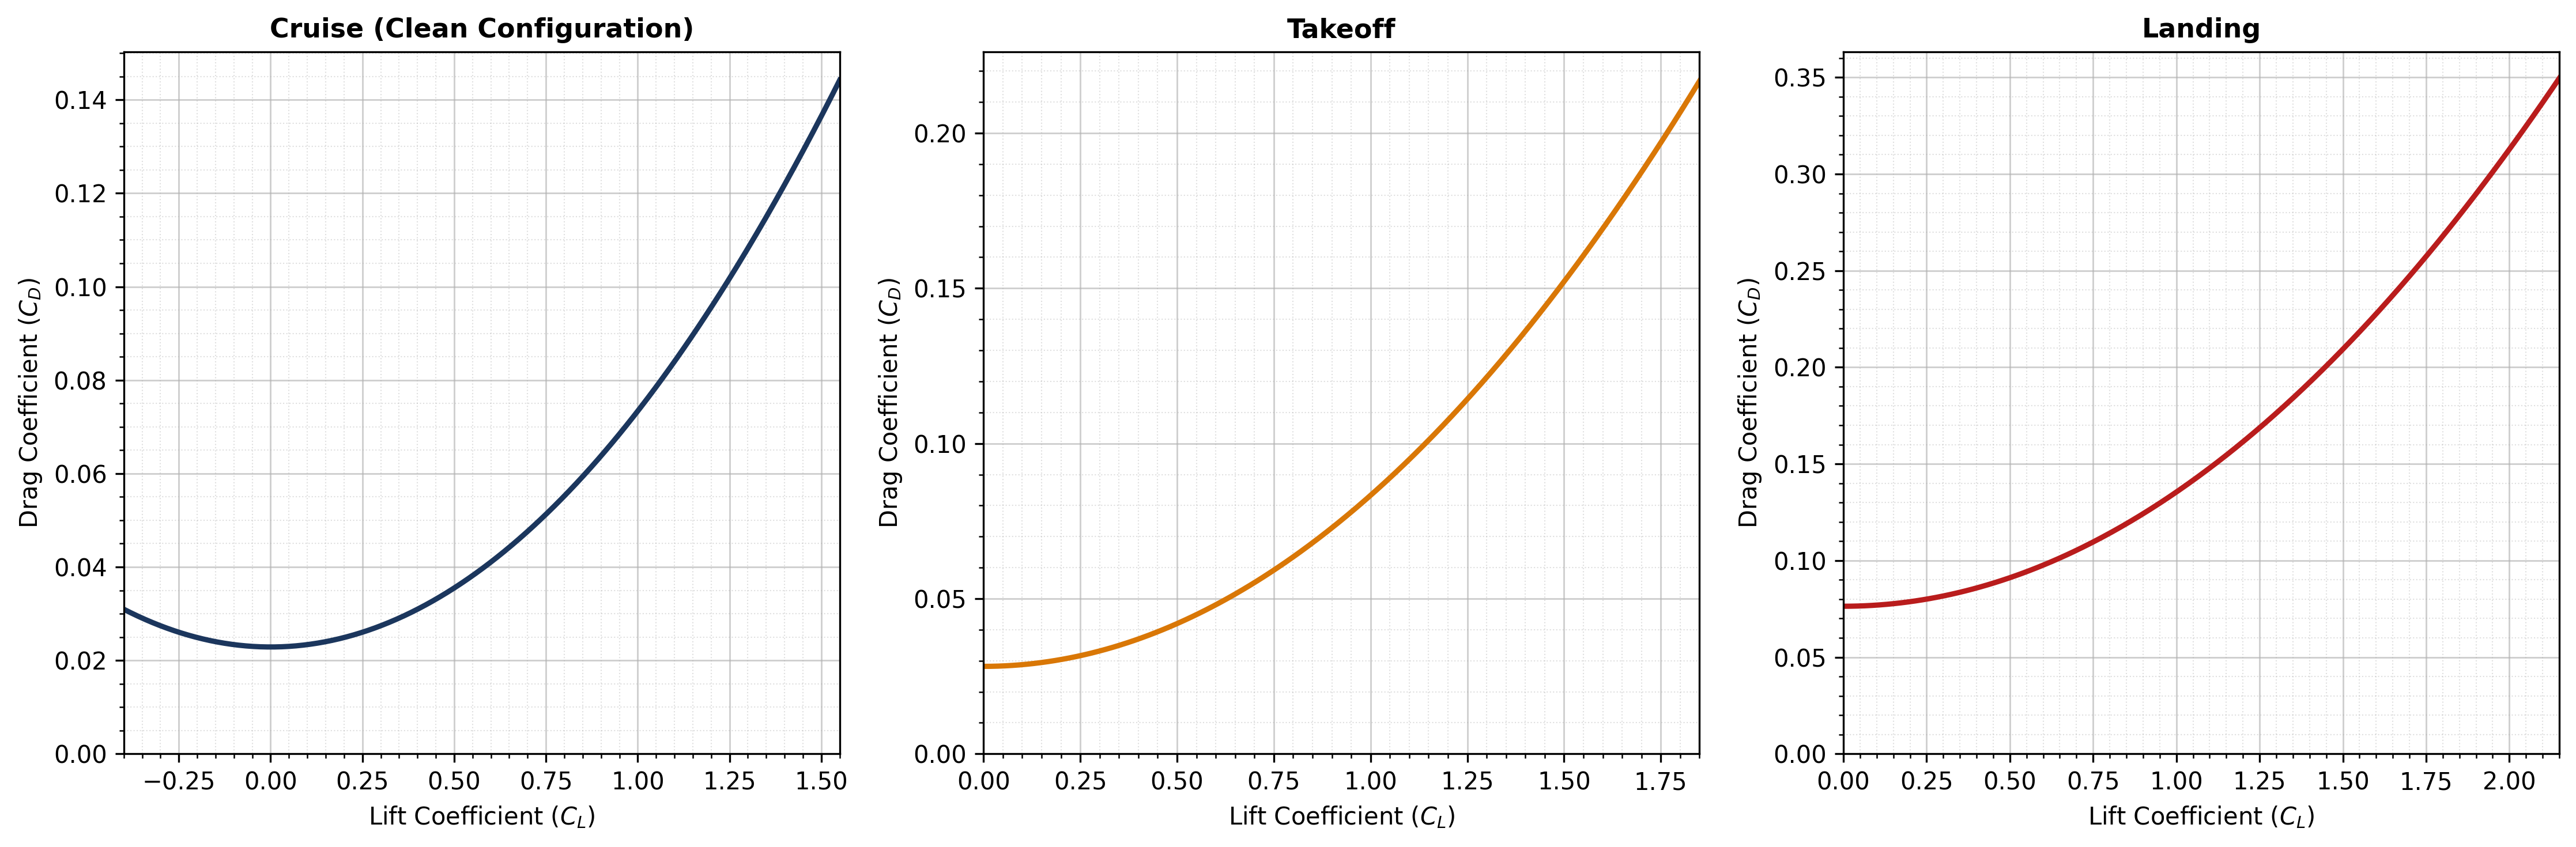

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. AIRCRAFT PARAMETERS
# ==============================================================================

# --- Cruise (Clean Configuration) ---
CD0_cruise = 0.02287
K_cruise = 0.0505
CL_min_cruise, CL_max_cruise = -0.40, 1.55

# --- Takeoff ---
CD0_takeoff = 0.02818
K_takeoff = 0.0551
CL_min_takeoff, CL_max_takeoff = 0.00, 1.85

# --- Landing ---
CD0_landing = 0.07635
K_landing = 0.0591
CL_min_landing, CL_max_landing = 0.00, 2.15


# ==============================================================================
# 2. DRAG POLAR CALCULATION
# CD = CD0 + K * CL^2
# ==============================================================================

# Cruise
CL_cruise = np.linspace(CL_min_cruise, CL_max_cruise, 300)
CD_cruise = CD0_cruise + K_cruise * CL_cruise**2

# Takeoff
CL_takeoff = np.linspace(CL_min_takeoff, CL_max_takeoff, 300)
CD_takeoff = CD0_takeoff + K_takeoff * CL_takeoff**2

# Landing
CL_landing = np.linspace(CL_min_landing, CL_max_landing, 300)
CD_landing = CD0_landing + K_landing * CL_landing**2


# ==============================================================================
# 3. PLOT SETTINGS
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300)

# --- Cruise ---
axes[0].plot(
    CL_cruise, CD_cruise,
    color='#1b365d',
    linewidth=2.2
)

axes[0].set_title('Cruise (Clean Configuration)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Lift Coefficient ($C_L$)', fontsize=10)
axes[0].set_ylabel('Drag Coefficient ($C_D$)', fontsize=10)
axes[0].set_xlim(CL_min_cruise, CL_max_cruise)
axes[0].set_ylim(bottom=0)
axes[0].grid(True, linestyle=':', linewidth=0.7, alpha=0.75)


# --- Takeoff ---
axes[1].plot(
    CL_takeoff, CD_takeoff,
    color='#d97706',
    linewidth=2.2
)

axes[1].set_title('Takeoff', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Lift Coefficient ($C_L$)', fontsize=10)
axes[1].set_ylabel('Drag Coefficient ($C_D$)', fontsize=10)
axes[1].set_xlim(CL_min_takeoff, CL_max_takeoff)
axes[1].set_ylim(bottom=0)
axes[1].grid(True, linestyle=':', linewidth=0.7, alpha=0.75)


# --- Landing ---
axes[2].plot(
    CL_landing, CD_landing,
    color='#b91c1c',
    linewidth=2.2
)

axes[2].set_title('Landing', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Lift Coefficient ($C_L$)', fontsize=10)
axes[2].set_ylabel('Drag Coefficient ($C_D$)', fontsize=10)
axes[2].set_xlim(CL_min_landing, CL_max_landing)
axes[2].set_ylim(bottom=0)
axes[2].grid(True, linestyle=':', linewidth=0.7, alpha=0.75)

# Grid formatting for all three plots
for ax in axes:
    ax.minorticks_on()
    ax.grid(
        True,
        which='major',
        linestyle='-',
        linewidth=0.7,
        alpha=0.6
    )
    ax.grid(
        True,
        which='minor',
        linestyle=':',
        linewidth=0.5,
        alpha=0.4
    )
# ==============================================================================
# 4. FINAL FORMATTING AND EXPORT
# ==============================================================================

plt.tight_layout()

plt.savefig('drag_polar_separate.png', dpi=300, bbox_inches='tight')

plt.show()
